In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np, os
import matplotlib.pyplot as plt

from pathlib import Path
import yaml
import re

import pyarrow as pa
import pyarrow.parquet as pq

import vivarium.gbd_mapping as gm
from vivarium.artifact import Artifact

# from db_queries import get_ids, get_outputs, get_population, get_covariate_estimates
# from get_draws.api import get_draws

import vivarium_helpers as vh
# import vivarium_helpers.id_helper as idh
from vivarium_helpers.vph_output.operations import VPHOperator

!date
!whoami
!pwd

Mon Nov  2 09:35:25 PST 2026
lutzes
/mnt/share/homes/lutzes/vivarium_research_alzheimers/verification_and_validation


# Find data

In [3]:
# Project directory on the cluster
project_dir = '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/'

if os.sys.platform == 'darwin':
    # Notebook is running on Nathaniel's MacBook
    local_project_dir = "/Users/ndbs/project_data/vivarium_csu_alzheimers/"
else:
    # Assume we're running on the cluster
    local_project_dir = project_dir

In [4]:
# Project directory
%cd $local_project_dir

/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers


In [5]:
# Results directory containing model 7.6 results for all locations
model_run_subdir = 'results/model14.0/model_spec/2026_10_30_13_30_29'
!ls -halt $model_run_subdir/results

total 64K
drwxrwsr-x  5 sbachmei IHME-Simulationscience 4.0K Oct 30 15:29 ..
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 transition_count_alzheimers_disease_and_other_dementias
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 person_time_alzheimers_disease_and_other_dementias
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 ylls
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 deaths
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 ylds
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 treatment_duration
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 transition_count_treatment
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 person_time_treatment
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 person_time_ever_eligible_for_bbbm_testing
drwxr-sr-x  2 sbachmei IHME-Simulationscience 4.3M Oct 30 15:27 person_time_eligible_for_bbbm_testing
drwxr-sr-x

In [6]:
locations = [
    'United States of America',
    'Brazil',
    'China',
    'Germany',
    'Israel',
    'Japan',
    'Spain',
    'Sweden',
    'Taiwan',
    'United Kingdom',
]

# Define some shorter names to use for plotting
location_to_short_name = ({loc: loc for loc in locations}| {
    'United Kingdom': 'UK',
    'United States of America': 'USA',
})

# Select a subset of locations to draw plots for
# locations_to_plot = locations[:2]

# project_dir = '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/'

artifact_model_number = '13.0' # Artifacts are stored here
run_subdirectories = [
    model_run_subdir,
]
# Where results are stored locally
run_dirs = [local_project_dir + run_subdir for run_subdir in run_subdirectories]
results_dirs = [run_dir + '/results/' for run_dir in run_dirs]

# # Option 1: One results directory per location
# location_to_results_dir = {
#     loc: path for loc, path in zip(locations, results_dirs)}

# Option 2: All locations in one results directory
location_to_results_dir = {'all': results_dirs[0]}

location_to_artifact_subdir = {loc: loc.lower().replace(' ', '_') for loc in locations}
artifact_subpaths = [f'artifacts/model{artifact_model_number}/' + subdir + '.hdf' for subdir in location_to_artifact_subdir.values()]
# Map locations to where artifacts are stored locally (for reading artifact data)
location_to_local_artifact_path = {
    loc: local_project_dir + subpath for loc, subpath in zip(locations, artifact_subpaths)}
# Map locations to where artifacts are stored on the cluster (for adding locations to sim results)
location_to_artifact_path = {loc: project_dir + subpath for loc, subpath in zip(locations, artifact_subpaths)}
# artifact_path_to_location = {path: loc for loc, path in location_to_artifact_path.items()}
# artifact_path_to_location = {project_dir + subpath: loc for subpath, loc in zip(artifact_subpaths, locations)}
location_to_artifact_path

{'United States of America': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/united_states_of_america.hdf',
 'Brazil': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/brazil.hdf',
 'China': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/china.hdf',
 'Germany': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/germany.hdf',
 'Israel': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/israel.hdf',
 'Japan': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/japan.hdf',
 'Spain': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/spain.hdf',
 'Sweden': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/sweden.hdf',
 'Taiwan': '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/

In [7]:
results_dirs

['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/results/model14.0/model_spec/2026_10_30_13_30_29/results/']

In [8]:
d = results_dirs[0]
!ls $d

counts_baseline_tests_among_eligible
counts_bbbm_tests
counts_new_simulants
counts_newly_eligible_for_bbbm_testing
deaths
person_time_alzheimers_disease_and_other_dementias
person_time_eligible_for_bbbm_testing
person_time_ever_eligible_for_bbbm_testing
person_time_treatment
transition_count_alzheimers_disease_and_other_dementias
transition_count_treatment
treatment_duration
ylds
ylls


# Get list of draws and draw columns from `keyspace.yaml`, and reduce to a subset of draws to save memory and time

In [9]:
with open(run_dirs[0] + '/keyspace.yaml', 'r') as keyspace_file:
    keyspace = yaml.safe_load(keyspace_file)
draws = keyspace['input_draw']
print(draws)

[202, 170, 164, 135, 243, 181, 197, 35, 11, 75, 41, 26, 216, 105, 15, 198, 233, 179, 19, 156, 172, 90, 96, 177, 24]


In [10]:
# I ended up never actually using this -- I just used all the draws
draws = sorted(draws[:]) # reduce to a subset of draws to save memory, and sort
draw_cols = [f'draw_{i}' for i in draws]
print(draw_cols)

['draw_11', 'draw_15', 'draw_19', 'draw_24', 'draw_26', 'draw_35', 'draw_41', 'draw_75', 'draw_90', 'draw_96', 'draw_105', 'draw_135', 'draw_156', 'draw_164', 'draw_170', 'draw_172', 'draw_177', 'draw_179', 'draw_181', 'draw_197', 'draw_198', 'draw_202', 'draw_216', 'draw_233', 'draw_243']


# Define some ordered Categorical dtypes, and convert years to ints

In [11]:
# Order locations lexicographically
all_locations = [
    'United States of America',
    'Brazil',
    'China',
    'Germany',
    'Israel',
    'Japan',
    'Spain',
    'Sweden',
    'Taiwan',
    'United Kingdom',
]
location_dtype = pd.CategoricalDtype(sorted(all_locations), ordered=True)

# Order years chronologically (for some reason years are strings in the output)
# years = [str(year) for year in range(2025, 2101)]
# year_dtype = pd.CategoricalDtype(years, ordered=True)
# int16 ranges from -32768 to 32767 (I think), which is sufficient to
# represent all years 2025-2100. uint8 only goes from 0 to 255, which is
# too small.
year_dtype = 'int16'

# Order age groups chronologically
age_groups = [f'{age}_to_{age + 4}' for age in range(25, 95, 5)] + ['95_plus']
age_group_dtype = pd.CategoricalDtype(age_groups, ordered=True)

# Order scenarios by complexity. Each testing speed has a scenario with
# zero impact treatment and a scenario with treatment.
testing_speeds = ['slow', 'intermediate', 'accelerated']
zero_impact_scenarios = [
    f'{speed}_testing_zero_impact_treatment' for speed in testing_speeds]
with_treatment_scenarios = [
    f'{speed}_testing_with_treatment' for speed in testing_speeds]
scenarios = ['baseline'] + zero_impact_scenarios + with_treatment_scenarios
scenario_dtype = pd.CategoricalDtype(scenarios, ordered=True)

colname_to_dtype = {
    'location': location_dtype,
    'event_year': year_dtype,
    'age_group': age_group_dtype,
    'scenario': scenario_dtype,
}

# Load one artifact and define age bins

In [12]:
usa_artifact_path = location_to_local_artifact_path['United States of America']
usa_art = Artifact(usa_artifact_path)
print(usa_art.load('metadata.locations'))


['United States of America']


In [13]:
# age_bins is an empty DataFrame with a MultiIndex storing age group data
age_bins = usa_art.load('population.age_bins')
age_dictionary = (
    age_bins
    .reset_index()
    .assign(age_group=lambda df: df['age_group_name'].str.replace(' ', '_'))
    # Filter to ages that actually appear in our sim
    .query("age_start >= 25")
)
age_dictionary

,age_group_id,age_group_name,age_start,age_end,age_group
4,10,25 to 29,25.0,30.0,25_to_29
5,11,30 to 34,30.0,35.0,30_to_34
6,12,35 to 39,35.0,40.0,35_to_39
7,13,40 to 44,40.0,45.0,40_to_44
8,14,45 to 49,45.0,50.0,45_to_49
9,15,50 to 54,50.0,55.0,50_to_54
10,16,55 to 59,55.0,60.0,55_to_59
11,17,60 to 64,60.0,65.0,60_to_64
12,18,65 to 69,65.0,70.0,65_to_69
13,19,70 to 74,70.0,75.0,70_to_74


# Define functions to load and merge Artifact data from all locations, and to summarize Artifact data for plotting

In [14]:
def load_artifact_data(
    key,
    filter_terms=None,
    location_to_artifact_path=location_to_local_artifact_path,
):
    dfs = {} # dict to map locations to artifact data
    for location, path in location_to_artifact_path.items():
        art = Artifact(path, filter_terms)
        # Check to make sure location matches artifact
        art_locations = art.load('metadata.locations')
        assert len(art_locations) == 1 and art_locations[0] == location, \
            f'Unexpected locations in artifact: {location=}, {art_locations=}'
        df = art.load(key)
        dfs[location] = df
    data = pd.concat(dfs, names=['location', *df.index.names])
    return data

def lower(x):
    return x.quantile(0.025)

def upper(x):
    return x.quantile(0.975)

def summarize_artifact_data(df):
    summary = df.agg(['mean', lower, upper], axis='columns')
    return summary

# Load CSF and PET testing rates

In [15]:
# NOTE: Dropping level 1 of index because it is meaningless, containing
# all 0s: 
# https://github.com/ihmeuw/vivarium_csu_alzheimers/blob/7674a25da52e8b9ee23c0184a2e65c6f53aac335/src/vivarium_csu_alzheimers/data/loader.py#L487-L489
csf_rates = load_artifact_data('testing_rates.csf').droplevel(1)
pet_rates = load_artifact_data('testing_rates.pet').droplevel(1)
existing_test_rates = (
    pd.concat(
        {'csf': csf_rates, 'pet': pet_rates}, names=['test_type', 'location'])
    .rename_axis(columns='input_draw')
)
existing_test_rates

input_draw                            draw_0    draw_1    draw_2    draw_3  \
test_type location                                                           
csf       United States of America  0.086170  0.140511  0.102449  0.092320   
          Brazil                    0.105865  0.173411  0.126100  0.113509   
          China                     0.035023  0.057369  0.041717  0.037552   
          Germany                   0.148848  0.243818  0.177298  0.159596   
          Israel                    0.105865  0.173411  0.126100  0.113509   
          Japan                     0.105865  0.173411  0.126100  0.113509   
          Spain                     0.195811  0.320745  0.233237  0.209950   
          Sweden                    0.322372  0.528056  0.383988  0.345649   
          Taiwan                    0.105865  0.173411  0.126100  0.113509   
          United Kingdom            0.075618  0.123865  0.090071  0.081078   
pet       United States of America  0.172089  0.196148  0.165458  0.088834   
          Brazil                    0.170942  0.194840  0.164355  0.088241   
          China                     0.069983  0.079767  0.067286  0.036126   
          Germany                   0.183562  0.209225  0.176489  0.094756   
          Israel                    0.170942  0.194840  0.164355  0.088241   
          Japan                     0.170942  0.194840  0.164355  0.088241   
          Spain                     0.297141  0.338682  0.285691  0.153386   
          Sweden                    0.051627  0.058844  0.049637  0.026650   
          Taiwan                    0.170942  0.194840  0.164355  0.088241   
          United Kingdom            0.122757  0.139919  0.118027  0.063368   

input_draw                            draw_4    draw_5    draw_6    draw_7  \
test_type location                                                           
csf       United States of America  0.126445  0.062653  0.118921  0.087192   
          Brazil                    0.155928  0.076634  0.146575  0.107136   
          China                     0.051585  0.025353  0.048491  0.035443   
          Germany                   0.219236  0.107748  0.206087  0.150634   
          Israel                    0.155928  0.076634  0.146575  0.107136   
          Japan                     0.155928  0.076634  0.146575  0.107136   
          Spain                     0.288407  0.141744  0.271109  0.198161   
          Sweden                    0.474817  0.233359  0.446338  0.326240   
          Taiwan                    0.155928  0.076634  0.146575  0.107136   
          United Kingdom            0.111377  0.054738  0.104697  0.076526   
pet       United States of America  0.164784  0.180419  0.178008  0.223862   
          Brazil                    0.163686  0.179216  0.176821  0.222370   
          China                     0.067012  0.073370  0.072390  0.091037   
          Germany                   0.175770  0.192447  0.189875  0.238786   
          Israel                    0.163686  0.179216  0.176821  0.222370   
          Japan                     0.163686  0.179216  0.176821  0.222370   
          Spain                     0.284528  0.311524  0.307361  0.386535   
          Sweden                    0.049435  0.054126  0.053402  0.067159   
          Taiwan                    0.163686  0.179216  0.176821  0.222370   
          United Kingdom            0.117546  0.128699  0.126979  0.159688   

input_draw                            draw_8    draw_9  ...  draw_240  \
test_type location                                      ...             
csf       United States of America  0.096971  0.095522  ...  0.111280   
          Brazil                    0.119291  0.117490  ...  0.137078   
          China                     0.039465  0.038869  ...  0.045349   
          Germany                   0.167726  0.165193  ...  0.192733   
          Israel                    0.119291  0.117490  ...  0.137078   
          Japan                     0.119291  0.117490 

In [16]:
existing_test_rates.stack().rename('value').to_frame().head()

value
test_type location                 input_draw          
csf       United States of America draw_0      0.086170
                                   draw_1      0.140511
                                   draw_2      0.102449
                                   draw_3      0.092320
                                   draw_4      0.126445

In [17]:
summarize_artifact_data(existing_test_rates)

mean     lower     upper
test_type location                                              
csf       United States of America  0.110460  0.056535  0.162082
          Brazil                    0.136058  0.069030  0.200223
          China                     0.045012  0.022837  0.066239
          Germany                   0.191299  0.097057  0.281516
          Israel                    0.136058  0.069030  0.200223
          Japan                     0.136058  0.069030  0.200223
          Spain                     0.251656  0.127679  0.370337
          Sweden                    0.414311  0.210203  0.609701
          Taiwan                    0.136058  0.069030  0.200223
          United Kingdom            0.097184  0.049307  0.143016
pet       United States of America  0.149777  0.072846  0.225110
          Brazil                    0.148778  0.072361  0.223609
          China                     0.060909  0.029624  0.091545
          Germany                   0.159762  0.077703  0.240117
          Israel                    0.148778  0.072361  0.223609
          Japan                     0.148778  0.072361  0.223609
          Spain                     0.258614  0.125781  0.388690
          Sweden                    0.044933  0.021854  0.067533
          Taiwan                    0.148778  0.072361  0.223609
          United Kingdom            0.106841  0.051964  0.160579

# Define functions to load simulation output and summarize it for plotting

In [18]:
# Create an operator object
ops = VPHOperator()
ops.index_cols.append('location')

def load_sim_output(
        measure,
        results_dict=location_to_results_dir,
        # Pass None to skip filtering locations (when None, must also
        # pass assign_location=False or raw=True)
        location_to_artifact_path=location_to_artifact_path,
        # specify dtypes of certain columns
        colname_to_dtype=colname_to_dtype,
        drop_superfluous_cols=True, # drop redundant or empty columns
        # Sets the 'read_dictionary' key of kwargs, which is passed to
        # pyarrow.parquet.read_table()
        force_parquet_dictionaries=True,
        force_pandas_categoricals=True,
        aggregate_seeds=True,
        assign_location=True,
        raw=False, # Overrides other parameters if True
        **kwargs, # keyword args to pass to .read_parquet
    ):
    """Load simulation output from .parquet files for all locations,
    optionally reducing the size of the data when possible. Returns
    concatenated outputs with a 'location' column added.
    """
    # Override optional transformations if raw=True
    if raw:
        drop_superfluous_cols = False
        force_parquet_dictionaries = False
        force_pandas_categoricals = False
        aggregate_seeds = False
        assign_location = False

    # Determine whether results for all locations are stored in same
    # directory, or if different locations have different results
    # directories
    match location_to_results_dir:
        case {'all': _}:
            all_locations_together = True
        case _:
            all_locations_together = False
    
    if all_locations_together and assign_location and location_to_artifact_path is None:
        raise ValueError(
            "Must provide mapping of artifacts to locations  when" \
            " assign_location=True and all locations are concatenated" \
            " in the simulation outputs."
        )

    dfs = []
    for location, directory in results_dict.items():

        # NOTE: New Vivarium version stores each measure in a folder
        # instead of a single .parquet file
        parquet_file_path = Path(directory) / measure #f'{measure}.parquet'
        # The ParquetDataset object has a .schema attribute we can use
        # to get its column names and data types 
        parquet_dataset = pa.parquet.ParquetDataset(parquet_file_path)
        # # NOTE: This code no longer works with datasets stored in
        # # directories instead of single parquet files:
        # # Read the Parquet file's schema to get column names and data types
        # parquet_schema = pq.read_schema(parquet_file_path)

        if (
            all_locations_together
            and location_to_artifact_path is not None
        ):
            if 'artifact_path' in parquet_dataset.schema.names:
                # Filter to locations in list
                location_filter = (
                    'artifact_path',
                    'in',
                    list(location_to_artifact_path.values()),
                )
                user_filters = kwargs.get('filters') # Defaults to None
                kwargs['filters'] = add_parquet_AND_filter(
                    location_filter, user_filters)
                # TODO: Use logging not printing
                print(location_filter)
            else:
                print("'artifact_path' column missing from parquet file."
                      " Not filtering locations.")

        if force_parquet_dictionaries:
            # Read all columns as dictionaries except those containing 
            # floating point values
            kwargs['read_dictionary'] = [
                col.name for col in parquet_dataset.schema
                if not pa.types.is_floating(col.type)]

        # Read the parquet file
        df = pd.read_parquet(parquet_file_path, **kwargs)
        # df = parquet_dataset.read(**kwargs).to_pandas()

        if drop_superfluous_cols:
            # Drop redundant columns
            for col1, col2 in [
                ('input_draw', 'input_draw_number'),
                ('entity', 'sub_entity'),
            ]:
                if (col1 in df and col2 in df and df[col1].equals(df[col2])):
                    df.drop(columns=col2, inplace=True)
            # Drop empty columns (e.g., sub-entity)
            for col in df:
                if df[col].isna().all():
                    df.drop(columns=col, inplace=True)
        if colname_to_dtype is not None:
            # NOTE: If copy-on-write is enabled, copy keyword is ignored
            df = df.astype(
                # Must filter to avoid KeyError
                {c: dtype for c, dtype in colname_to_dtype.items() if c in df},
                copy=False
            )
        if force_pandas_categoricals:
            convert_to_categorical(
                df, exclude_cols=colname_to_dtype or (), inplace=True)
        if aggregate_seeds:
            # Use default index and value columns when aggregating
            df = vh.vph_output.operations.marginalize(df, 'random_seed')
        if assign_location:
            if all_locations_together:
                # NOTE: location_to_artifact_path is guaranteed not to
                # be None because assign_location and
                # all_locations_together are both True

                # Create a Categorical dtype with all locations
                location_dtype = pd.CategoricalDtype(
                    sorted(location_to_artifact_path.keys()), ordered=True)
                # Invert the dictionary so we can map artifact paths to
                # locations
                artifact_path_to_location = {
                    path: loc for loc, path
                    in location_to_artifact_path.items()}
                if 'artifact_path' in df:
                    df['location'] = df['artifact_path'].map(
                        artifact_path_to_location).astype(location_dtype)
                else:
                    # In case the engineers change the DataFrame format
                    # on us...
                    print("'artifact_path' column missing from DataFrame."
                          " Not assigning locations.")
            else:
                # NOTE: location_to_results_dir contains actual
                # locations as keys (not 'all') since
                # all_locations_together is False

                # Create a Categorical dtype with all locations to avoid
                # converting back to object dtype.
                location_dtype = pd.CategoricalDtype(
                    sorted(location_to_results_dir.keys()), ordered=True)
                df['location'] = location
                df['location'] = df['location'].astype(location_dtype)
        dfs.append(df)
    # TODO: Maybe if assign_location is False and all_locations_together
    # is also False (and there is more than one location?), we should
    # return a dict mapping locations to dataframes (or just a list of
    # dataframes?) instead of concatenating, since it won't be possible
    # to filter the resulting concatenated dataframe by location...
    df = pd.concat(dfs)
    return df

# # NOTE: This function is unnecessary because it does the same thing as
# # DataFrame.astype
# def convert_dtypes(df, colname_to_dtype, inplace=False):
#     if not inplace:
#         df = df.copy()
#     for colname, dtype in colname_to_dtype.items():
#         if colname in df:
#             df[colname] = df[colname].astype(dtype)

#     if not inplace:
#         return df
#     else:
#         return None

# TODO: Consider making certain columns ordered Categoricals
def convert_to_categorical(
        df,
        include_cols=(),
        exclude_cols=(),
        exclude_dtypes=(pd.api.types.is_numeric_dtype,
                        # TODO: For some reason,
                        # pd.api.types.is_categorical_dtype is deprecated, and
                        # they recommend using isinstance instead. So I don't
                        # know if there's a simpler way to make checking for a
                        # categorical dtype more parallel with checking for a
                        # numeric dtype.
                        lambda dtype: isinstance(dtype, pd.CategoricalDtype)),
        inplace=False
    ):
    """Convert all columns except numerical columns to categorical. This
    saves lots of memory, allowing us to load and manipulate larger
    DataFrames.
    """
    if  len(set(include_cols).intersection(exclude_cols)) != 0:
        raise ValueError("A column can't be both included and excluded!")
    if not inplace:
        df = df.copy()
    for col in df:
        if (
            col in include_cols
            or (col not in exclude_cols
                and not any(excluded_dtype(df[col].dtype)
                            for excluded_dtype in exclude_dtypes))
                # and df[col].dtype not in exclude_dtypes)
        ):
            df[col] = df[col].astype('category')
    if not inplace:
        return df
    else:
        return None
    
def add_parquet_AND_filter(new_filter, existing_filters):
    match existing_filters:
        case None:
            # No existing filters -- create a single AND group
            filters = [new_filter]
        case list([tuple((_, _, _)), *_]):
            # Existing filters consist of one AND group -- add the new filter
            filters = [new_filter, *existing_filters]
        case list([list([tuple((_, _, _)), *_]), *_]):
            # Add the filter to each AND group in the outer OR group
            filters = [[new_filter, *and_group] for and_group in existing_filters]
        case _:
            raise ValueError(f"Malformed parquet filter: {existing_filters}")
    # # Alternate version using isinstance()
    # if existing_filters is None:
    #     # No existing filters -- create a single AND group
    #     filters = [new_filter]
    # elif isinstance(existing_filters[0], tuple):
    #     # Existing filters consist of one AND group -- add the new filter
    #     filters = [new_filter, *existing_filters]
    # elif isinstance(existing_filters[0], list):
    #     # Add the filter to each AND group in the outer OR group
    #     filters = [[new_filter, *and_group] for and_group in existing_filters]
    # else:
    #     raise ValueError(f"Malformed parquet filter: {existing_filters}")
    return filters

# NOTE: Need to create ops before defining this function
def summarize_sim_data(df, age_dictionary=age_dictionary):
    """Summarize simulation data for plotting."""
    # Merge to get an age_start column for plotting
    if 'age_group' in df:
        df = df.merge(age_dictionary, on='age_group')
    # Summarize, and rename percentiles to match artifact
    summary = ops.describe(df).rename(
        columns={'2.5%': 'lower', '97.5%': 'upper'})
    return summary

def print_memory_usage(df):
    print(df.memory_usage(deep=True).sum() / 1e6, 'MB')


# Load baseline test counts

In [19]:
# On the first attempt, this resulted in an empty DataFrame. Using
# raw=True, I determined that the .groupby was failing because of NaNs
# in the sub_entity column, since dropna=True by default.
existing_tests = load_sim_output(
    'counts_baseline_tests_among_eligible',
    # location_to_artifact_path=None,
    # raw=True,
)
# Memory usage is almost 3 GB when loading without Categoricals
print_memory_usage(existing_tests)
existing_tests

('artifact_path', 'in', ['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/united_states_of_america.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/brazil.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/china.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/germany.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/israel.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/japan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/spain.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/sweden.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/taiwan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/mo

,age_group,artifact_path,entity,entity_type,event_year,input_draw,measure,scenario,sex,sub_entity,testing_state,value,location
0,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2022,11,counts_baseline_tests_among_eligible,baseline,Female,,not_tested,0.0,Spain
1,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2022,11,counts_baseline_tests_among_eligible,baseline,Female,,csf,0.0,Spain
2,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2022,11,counts_baseline_tests_among_eligible,baseline,Female,,pet,0.0,Spain
3,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2022,11,counts_baseline_tests_among_eligible,baseline,Female,,bbbm,0.0,Spain
4,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2022,11,counts_baseline_tests_among_eligible,baseline,Male,,not_tested,0.0,Spain
...,...,...,...,...,...,...,...,...,...,...,...,...,...
16589995,95_plus,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2100,243,counts_baseline_tests_among_eligible,accelerated_testing_with_treatment,Female,,bbbm,8.0,Brazil
16589996,95_plus,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2100,243,counts_baseline_tests_among_eligible,accelerated_testing_with_treatment,Male,,not_tested,261.0,Brazil
16589997,95_plus,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2100,243,counts_baseline_tests_among_eligible,accelerated_testing_with_treatment,Male,,csf,10.0,Brazil
16589998,95_plus,/mnt/team/simulation_science/pub/models/vivari...,baseline_testing,testing,2100,243,counts_baseline_tests_among_eligible,accelerated_testing_with_treatment,Male,,pet,89.0,Brazil


In [20]:
# # Column doesn't exist when using simulate for one location instead of
# # psimulate for multpile locations
# existing_tests.artifact_path.unique()

In [21]:
existing_tests.location.unique()

['Spain', 'United Kingdom', 'Sweden', 'Germany', 'Israel', 'China', 'Taiwan', 'Japan', 'United States of America', 'Brazil']
Categories (10, object): ['Brazil' < 'China' < 'Germany' < 'Israel' ... 'Sweden' < 'Taiwan' < 'United Kingdom' < 'United States of America']

In [22]:
# Check memory usage -- loading it raw, it took up 2.1 GB
existing_tests.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16590000 entries, 0 to 16589999
Data columns (total 13 columns):
 #   Column         Dtype   
---  ------         -----   
 0   age_group      category
 1   artifact_path  category
 2   entity         category
 3   entity_type    category
 4   event_year     int16   
 5   input_draw     int64   
 6   measure        category
 7   scenario       category
 8   sex            category
 9   sub_entity     category
 10  testing_state  category
 11  value          float64 
 12  location       category
dtypes: category(10), float64(1), int16(1), int64(1)
memory usage: 443.0 MB


In [23]:
# See if there is only one measure, or more
existing_tests.measure.unique()

['counts_baseline_tests_among_eligible']
Categories (1, object): ['counts_baseline_tests_among_eligible']

In [24]:
# Check whether all values are integers -- yes
(existing_tests.value % 1).unique()

array([0.])

# Divide to calculate CSF/PET testing rates from sim

In [25]:
sim_test_rates = ops.ratio(
    existing_tests,
    existing_tests,
    strata = ['event_year'],
    numerator_broadcast='testing_state',
)
sim_test_rates

,event_year,testing_state,input_draw,scenario,location,value,numerator_measure,denominator_measure,multiplier
0,2022,not_tested,11,accelerated_testing_with_treatment,Brazil,0.758662,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
1,2022,csf,11,accelerated_testing_with_treatment,Brazil,0.138288,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
2,2022,pet,11,accelerated_testing_with_treatment,Brazil,0.103050,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
3,2022,bbbm,11,accelerated_testing_with_treatment,Brazil,0.000000,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
4,2022,not_tested,11,accelerated_testing_with_treatment,China,0.910258,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
...,...,...,...,...,...,...,...,...,...
552995,2100,bbbm,243,slow_testing_zero_impact_treatment,United Kingdom,0.089568,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
552996,2100,not_tested,243,slow_testing_zero_impact_treatment,United States of America,0.702111,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
552997,2100,csf,243,slow_testing_zero_impact_treatment,United States of America,0.024146,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
552998,2100,pet,243,slow_testing_zero_impact_treatment,United States of America,0.205509,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1


In [26]:
sim_test_rates.query("scenario=='baseline'")

,event_year,testing_state,input_draw,scenario,location,value,numerator_measure,denominator_measure,multiplier
80,2022,not_tested,11,baseline,Brazil,0.758662,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
81,2022,csf,11,baseline,Brazil,0.138288,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
82,2022,pet,11,baseline,Brazil,0.103050,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
83,2022,bbbm,11,baseline,Brazil,0.000000,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
84,2022,not_tested,11,baseline,China,0.910258,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
...,...,...,...,...,...,...,...,...,...
552835,2100,bbbm,243,baseline,United Kingdom,0.000000,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
552836,2100,not_tested,243,baseline,United States of America,0.735859,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
552837,2100,csf,243,baseline,United States of America,0.028094,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1
552838,2100,pet,243,baseline,United States of America,0.236047,counts_baseline_tests_among_eligible,counts_baseline_tests_among_eligible,1


In [27]:
existing_test_rates

input_draw                            draw_0    draw_1    draw_2    draw_3  \
test_type location                                                           
csf       United States of America  0.086170  0.140511  0.102449  0.092320   
          Brazil                    0.105865  0.173411  0.126100  0.113509   
          China                     0.035023  0.057369  0.041717  0.037552   
          Germany                   0.148848  0.243818  0.177298  0.159596   
          Israel                    0.105865  0.173411  0.126100  0.113509   
          Japan                     0.105865  0.173411  0.126100  0.113509   
          Spain                     0.195811  0.320745  0.233237  0.209950   
          Sweden                    0.322372  0.528056  0.383988  0.345649   
          Taiwan                    0.105865  0.173411  0.126100  0.113509   
          United Kingdom            0.075618  0.123865  0.090071  0.081078   
pet       United States of America  0.172089  0.196148  0.165458  0.088834   
          Brazil                    0.170942  0.194840  0.164355  0.088241   
          China                     0.069983  0.079767  0.067286  0.036126   
          Germany                   0.183562  0.209225  0.176489  0.094756   
          Israel                    0.170942  0.194840  0.164355  0.088241   
          Japan                     0.170942  0.194840  0.164355  0.088241   
          Spain                     0.297141  0.338682  0.285691  0.153386   
          Sweden                    0.051627  0.058844  0.049637  0.026650   
          Taiwan                    0.170942  0.194840  0.164355  0.088241   
          United Kingdom            0.122757  0.139919  0.118027  0.063368   

input_draw                            draw_4    draw_5    draw_6    draw_7  \
test_type location                                                           
csf       United States of America  0.126445  0.062653  0.118921  0.087192   
          Brazil                    0.155928  0.076634  0.146575  0.107136   
          China                     0.051585  0.025353  0.048491  0.035443   
          Germany                   0.219236  0.107748  0.206087  0.150634   
          Israel                    0.155928  0.076634  0.146575  0.107136   
          Japan                     0.155928  0.076634  0.146575  0.107136   
          Spain                     0.288407  0.141744  0.271109  0.198161   
          Sweden                    0.474817  0.233359  0.446338  0.326240   
          Taiwan                    0.155928  0.076634  0.146575  0.107136   
          United Kingdom            0.111377  0.054738  0.104697  0.076526   
pet       United States of America  0.164784  0.180419  0.178008  0.223862   
          Brazil                    0.163686  0.179216  0.176821  0.222370   
          China                     0.067012  0.073370  0.072390  0.091037   
          Germany                   0.175770  0.192447  0.189875  0.238786   
          Israel                    0.163686  0.179216  0.176821  0.222370   
          Japan                     0.163686  0.179216  0.176821  0.222370   
          Spain                     0.284528  0.311524  0.307361  0.386535   
          Sweden                    0.049435  0.054126  0.053402  0.067159   
          Taiwan                    0.163686  0.179216  0.176821  0.222370   
          United Kingdom            0.117546  0.128699  0.126979  0.159688   

input_draw                            draw_8    draw_9  ...  draw_240  \
test_type location                                      ...             
csf       United States of America  0.096971  0.095522  ...  0.111280   
          Brazil                    0.119291  0.117490  ...  0.137078   
          China                     0.039465  0.038869  ...  0.045349   
          Germany                   0.167726  0.165193  ...  0.192733   
          Israel                    0.119291  0.117490  ...  0.137078   
          Japan                     0.119291  0.117490 

In [28]:
# CSF and PET testing rates across all draws
summarize_artifact_data(existing_test_rates).sort_index()

mean     lower     upper
test_type location                                              
csf       Brazil                    0.136058  0.069030  0.200223
          China                     0.045012  0.022837  0.066239
          Germany                   0.191299  0.097057  0.281516
          Israel                    0.136058  0.069030  0.200223
          Japan                     0.136058  0.069030  0.200223
          Spain                     0.251656  0.127679  0.370337
          Sweden                    0.414311  0.210203  0.609701
          Taiwan                    0.136058  0.069030  0.200223
          United Kingdom            0.097184  0.049307  0.143016
          United States of America  0.110460  0.056535  0.162082
pet       Brazil                    0.148778  0.072361  0.223609
          China                     0.060909  0.029624  0.091545
          Germany                   0.159762  0.077703  0.240117
          Israel                    0.148778  0.072361  0.223609
          Japan                     0.148778  0.072361  0.223609
          Spain                     0.258614  0.125781  0.388690
          Sweden                    0.044933  0.021854  0.067533
          Taiwan                    0.148778  0.072361  0.223609
          United Kingdom            0.106841  0.051964  0.160579
          United States of America  0.149777  0.072846  0.225110

In [29]:
# CSF and PET testing rates filtered to draws used in sim --
# the PET rate is slightly higher in all locations
summarize_artifact_data(existing_test_rates[draw_cols]).sort_index()

mean     lower     upper
test_type location                                              
csf       Brazil                    0.134294  0.037015  0.197653
          China                     0.044428  0.012245  0.065389
          Germany                   0.188820  0.052043  0.277903
          Israel                    0.134294  0.037015  0.197653
          Japan                     0.134294  0.037015  0.197653
          Spain                     0.248394  0.068463  0.365584
          Sweden                    0.408941  0.112714  0.601876
          Taiwan                    0.134294  0.037015  0.197653
          United Kingdom            0.095924  0.026439  0.141181
          United States of America  0.109041  0.030779  0.160014
pet       Brazil                    0.139836  0.070263  0.217425
          China                     0.057248  0.028765  0.089013
          Germany                   0.150159  0.075450  0.233477
          Israel                    0.139836  0.070263  0.217425
          Japan                     0.139836  0.070263  0.217425
          Spain                     0.243070  0.122134  0.377940
          Sweden                    0.042232  0.021220  0.065665
          Taiwan                    0.139836  0.070263  0.217425
          United Kingdom            0.100419  0.050457  0.156138
          United States of America  0.140774  0.070734  0.218884

In [30]:
(
    sim_test_rates.query(
        "scenario=='baseline' and event_year==2050"
        " and testing_state not in ['not_tested', 'bbbm']"
    )
    .drop(columns=['numerator_measure', 'denominator_measure',
                   'multiplier', 'scenario'])
    .pipe(ops.describe, percentiles=[.025, .975])
    .reorder_levels(['event_year', 'testing_state', 'location'])
    .sort_index()
)

count      mean       std  \
event_year testing_state location                                              
2050       csf           Brazil                     25.0  0.134336  0.045000   
                         China                      25.0  0.044402  0.014947   
                         Germany                    25.0  0.188815  0.063158   
                         Israel                     25.0  0.133843  0.044698   
                         Japan                      25.0  0.134262  0.044648   
                         Spain                      25.0  0.248092  0.082466   
                         Sweden                     25.0  0.410437  0.137110   
                         Taiwan                     25.0  0.134011  0.044837   
                         United Kingdom             25.0  0.095628  0.032225   
                         United States of America   25.0  0.108454  0.036266   
           pet           Brazil                     25.0  0.140653  0.047576   
                         China                      25.0  0.056938  0.019873   
                         Germany                    25.0  0.152031  0.050401   
                         Israel                     25.0  0.141126  0.047541   
                         Japan                      25.0  0.142203  0.047789   
                         Spain                      25.0  0.244009  0.081548   
                         Sweden                     25.0  0.041813  0.014231   
                         Taiwan                     25.0  0.141136  0.047621   
                         United Kingdom             25.0  0.101315  0.034154   
                         United States of America   25.0  0.141870  0.048034   

                                                        min      2.5%  \
event_year testing_state location                                       
2050       csf           Brazil                    0.031833  0.036907   
                         China                     0.010860  0.012580   
                         Germany                   0.046566  0.052577   
                         Israel                    0.032390  0.036579   
                         Japan                     0.033884  0.038491   
                         Spain                     0.061879  0.069393   
                         Sweden                    0.105616  0.113067   
                         Taiwan                    0.031936  0.037007   
                         United Kingdom            0.024478  0.026477   
                         United States of America  0.026989  0.030753   
           pet           Brazil                    0.071524  0.072149   
                         China                     0.028499  0.028698   
                         Germany                   0.079552  0.079593   
                         Israel                    0.071120  0.071550   
                         Japan                     0.069901  0.072107   
                         Spain                     0.124224  0.125684   
                         Sweden                    0.019807  0.019839   
                         Taiwan                    0.072094  0.072183   
                         United Kingdom            0.051440  0.051719   
                         United States of America  0.071329  0.072254   

                                                        50%     97.5%  \
event_year testing_state location                                       
2050       csf           Brazil                    0.133667  0.198380   
                         China                     0.043579  0.066601   
                         Germany                   0.192600  0.276297   
                         Israel                    0.134037  0.197100   
                         Japan                     0.134707  0.196360   
                         Spain                     0.251267  0.364671   
                         Sweden                    0.406279  0.607136   
                         T

# Plot test CSF/PET test rates

Let's make a grid of plots with one column for each scenario and one row
for each country. In each axes, plot testing rate over time, with one
line for each of the four testing states, and plot Artifact testing
rates in same color but different line style.

In [31]:
def plot_over_time_by_column(
        df,
        colname,
        ylabel='',
        title='',
        uncertainty=True,
        ax=None,
        plot_func='plot',
        style_col='auto',
        **kwargs, # Keyword args to pass to plotting function
    ):
    """Plot mean value vs. year for each value in the column `colname`,
    optionally with (lower, upper) uncertainty band.

    If `style_col` is a column name, draw one line for each pair of values
    in `colname` and `style_col`, with one color for each value of
    `colname` and one line style for each value of `style_col`. With the
    default 'auto', `style_col` is 'scenario' when df has more than one
    scenario, so that values are never averaged over scenarios.
    """
    if ax is None:
        ax = plt.gca()
    if style_col == 'auto':
        multiple_scenarios = (
            'scenario' in df and colname != 'scenario'
            and df['scenario'].nunique() > 1)
        style_col = 'scenario' if multiple_scenarios else None
    group_cols = [colname] if style_col is None else [colname, style_col]
    agg = df.groupby(group_cols + ['event_year'], observed=True)['value'].agg(['mean', lower, upper])
    linestyles = ['-', '--', ':', '-.']
    col_vals = agg.index.unique(colname)
    style_vals = [None] if style_col is None else agg.index.unique(style_col)
    ax_plotter = getattr(ax, plot_func)
    for color_num, col_val in enumerate(col_vals):
        color = f'C{color_num % 10}'
        for style_num, style_val in enumerate(style_vals):
            key = (col_val,) if style_col is None else (col_val, style_val)
            try:
                values = agg.xs(key, level=group_cols)
            except KeyError:
                # This pair of values does not occur in the data
                continue
            years = values.index
            label = f"{colname}={col_val}"
            line_kwargs = {'color': color}
            if style_col is not None:
                label += f", {style_col}={style_val}"
                line_kwargs['linestyle'] = linestyles[style_num % len(linestyles)]
            ax_plotter(years, values['mean'], label=label, **line_kwargs, **kwargs)
            if uncertainty:
                ax.fill_between(
                    years, values['lower'], values['upper'], color=color, alpha=.1)

    ax.set_xlabel('year')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax

def plot_over_time_by_column_for_row_x_1(
        df, colname, row_variable, ylabel='', suptitle='', uncertainty=True,
        axes_width=12, axes_height=6,
        plot_func='plot',
        **kwargs,
    ):
    """Draw a nx1 figure with rows indexed by location, calling plot_over_time_by_column()
    for each subplot.
    """
    # Get ordered list of locations in the dataframe
    # df = csr.to_ordered_categoricals(df)
    df = convert_to_categorical(df)
    row_values = df[row_variable].unique().sort_values()
    fig, _ = plt.subplots(
        len(row_values), 1,
        figsize=(axes_width, axes_height * len(row_values)))
    for row_num, row_value in enumerate(row_values):
        plot_over_time_by_column(
            df.query(f"{row_variable}==@row_value"),
            colname,
            ylabel,
            f"{row_variable}={row_value}",
            uncertainty,
            ax=fig.axes[row_num],
            plot_func=plot_func,
            **kwargs,
        )
    fig.suptitle(suptitle, fontsize=18)
    fig.tight_layout()
    return fig

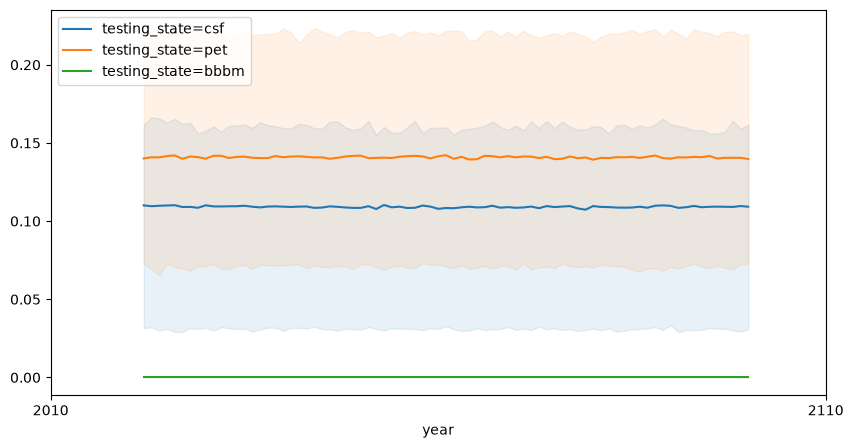

In [32]:
fig, ax = plt.subplots(figsize=(10,5))
plot_over_time_by_column(
    sim_test_rates
    .query("location == 'United States of America' and scenario == 'baseline' and testing_state != 'not_tested'"),
    'testing_state')
ax.set_xticks(ax.get_xticks()[::10])
# ax.tick_params(rotation=90)
plt.show()

# Plot existing test rates in baseline for each country

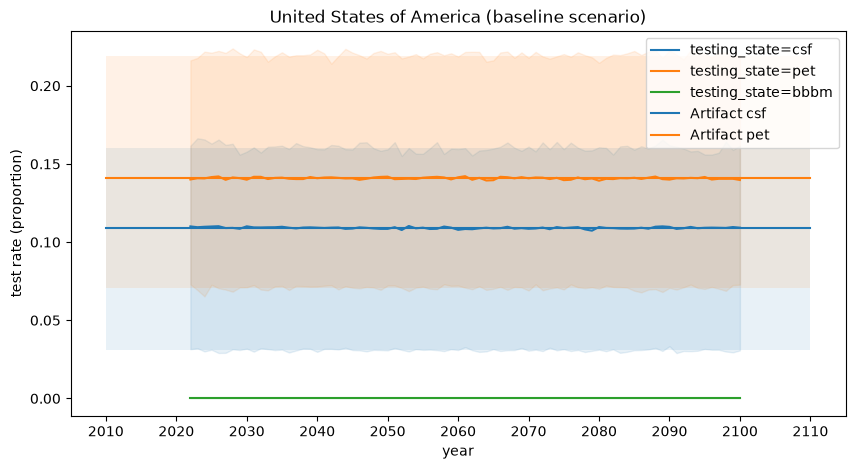

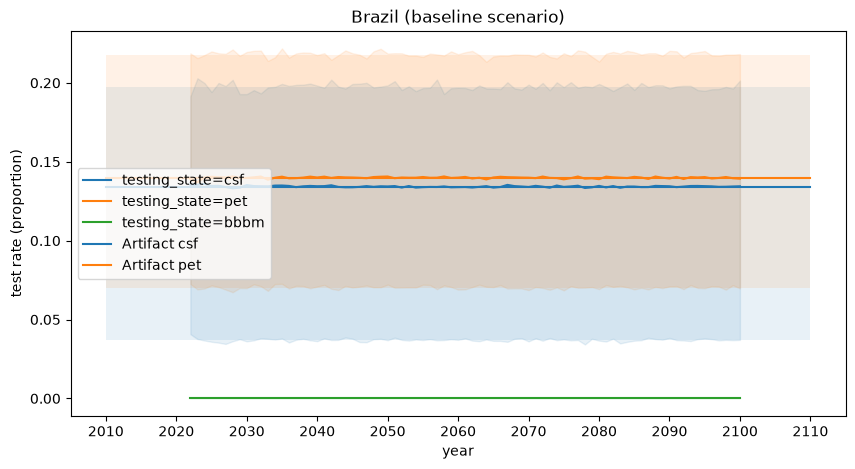

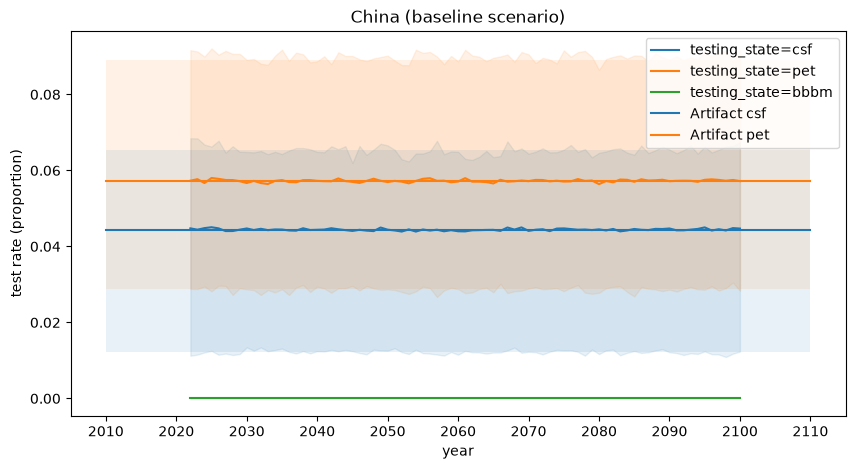

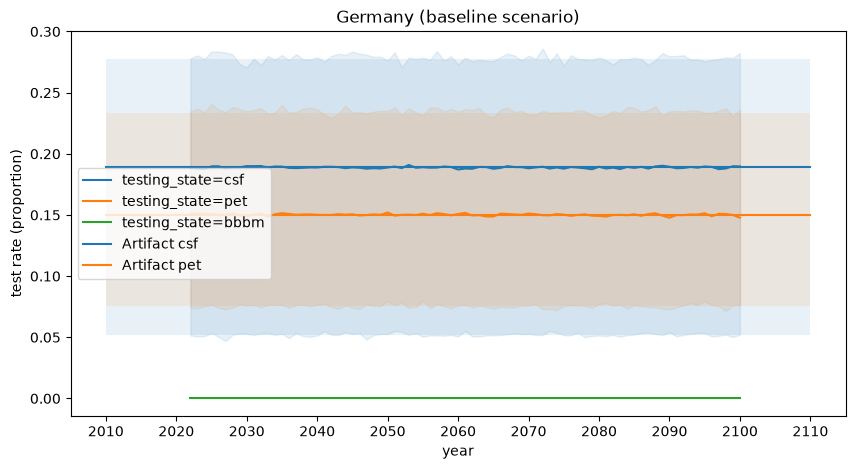

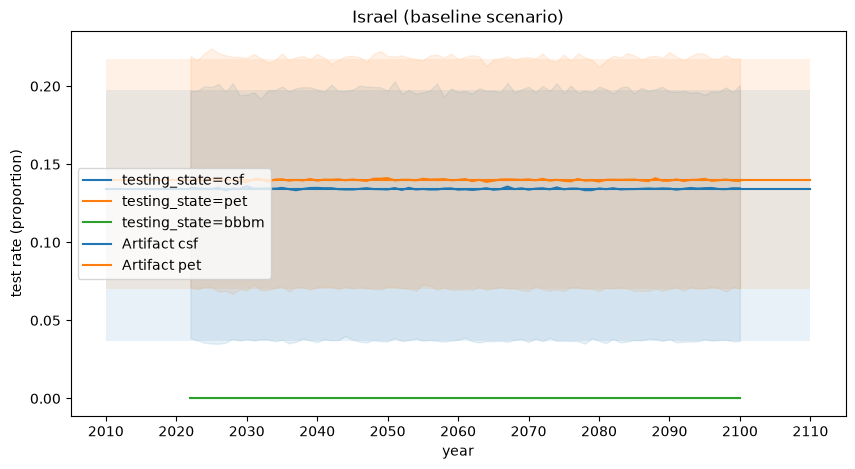

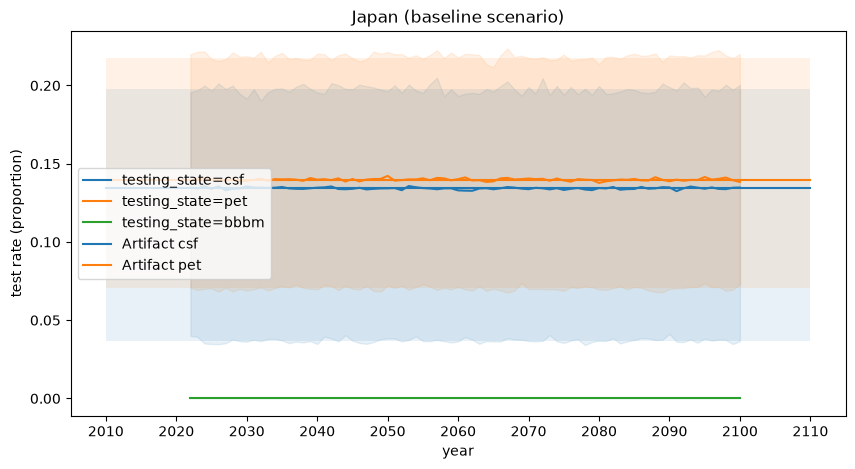

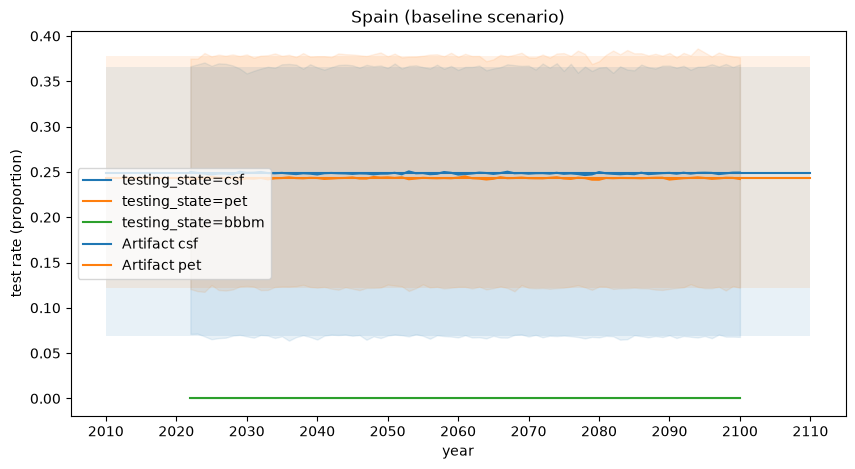

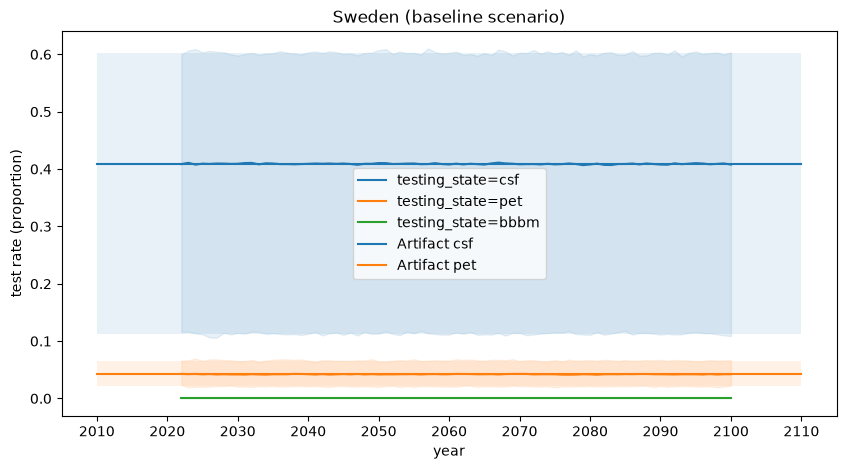

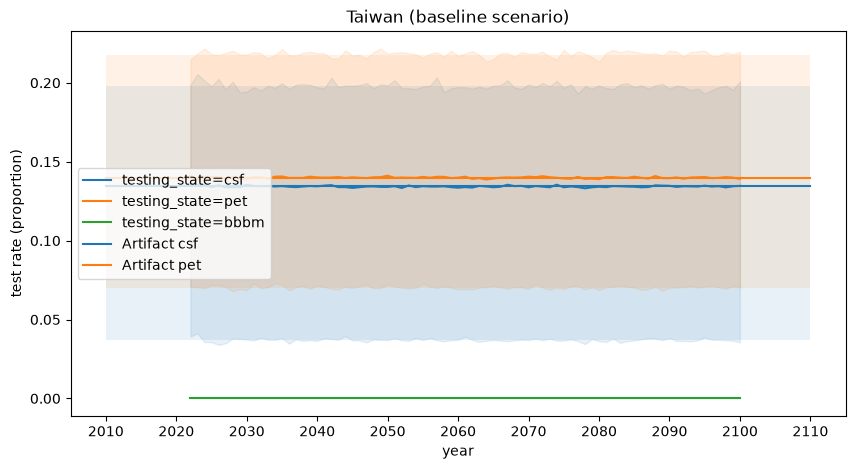

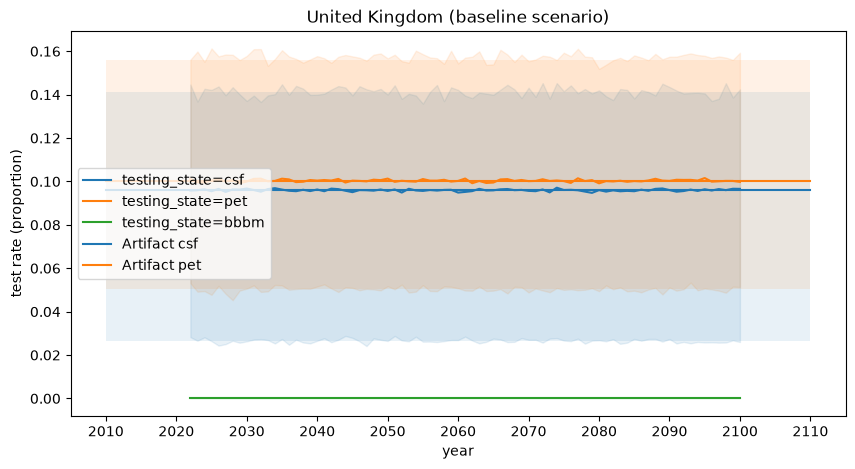

In [33]:
for location in locations:
    fig, ax = plt.subplots(figsize=(10,5))
    plot_over_time_by_column(
        sim_test_rates
        .query("location == @location and scenario == 'baseline' and testing_state != 'not_tested'"),
        'testing_state',
        ylabel='test rate (proportion)',
        title=location + ' (baseline scenario)',
    )
    filtered_x_ticks = ax.get_xticks()#[::5]
    ax.set_xticks(filtered_x_ticks)

    artifact_testing_data = summarize_artifact_data(
        # NOTE: PET testing rates look too high if we don't filter to
        # draws used in sim
        existing_test_rates[draw_cols]).query("location==@location")
    for test_type in artifact_testing_data.index.unique('test_type'):
        ax.plot(
            filtered_x_ticks,
            np.broadcast_to(artifact_testing_data.loc[test_type, 'mean'], (len(filtered_x_ticks),)),
            label=f'Artifact {test_type}'
        )
        ax.fill_between(
            filtered_x_ticks,
            np.broadcast_to(artifact_testing_data.loc[test_type, 'lower'], (len(filtered_x_ticks),)),
            np.broadcast_to(artifact_testing_data.loc[test_type, 'upper'], (len(filtered_x_ticks),)),
            alpha=.1,
        )
    # ax.tick_params(rotation=90)
    # ax.semilogy()
    # ax.set_ylim(0, 0.1)
    ax.legend()
    plt.show()

# Plot existing tests in baseline and zero impact treatment scenarios for one country

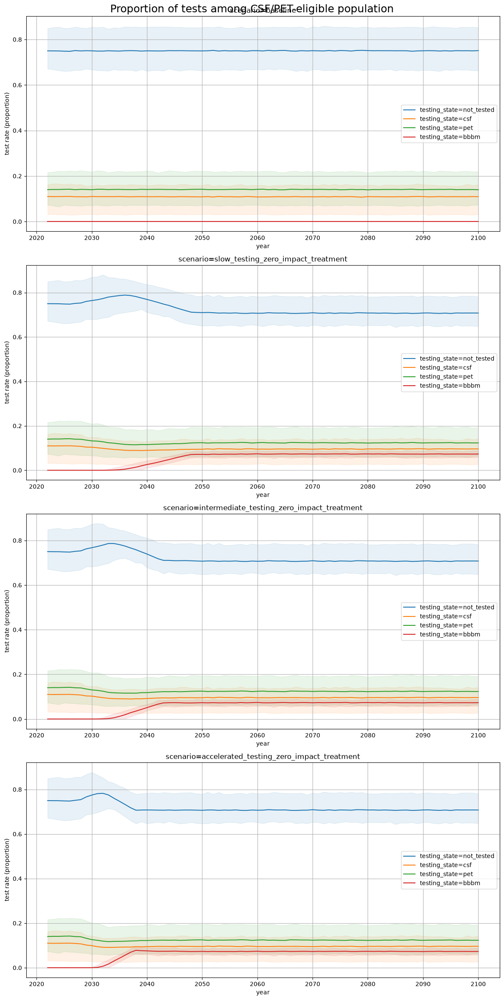

In [34]:
fig = plot_over_time_by_column_for_row_x_1(
    sim_test_rates.query(
        "location == 'United States of America'"
        " and (scenario == 'baseline' or scenario in @zero_impact_scenarios)"),
    'testing_state',
    'scenario',
    ylabel='test rate (proportion)',
    suptitle='Proportion of tests among CSF/PET-eligible population',
)
for ax in fig.axes:
    ax.grid(True)
#     ax.set_xticks(ax.get_xticks()[::5])
plt.show()

# Plot existing test rates in zero impact treatment scenarios for all countries

CSF now decreases at the same time as PET testing. Looks like the bugfix worked.

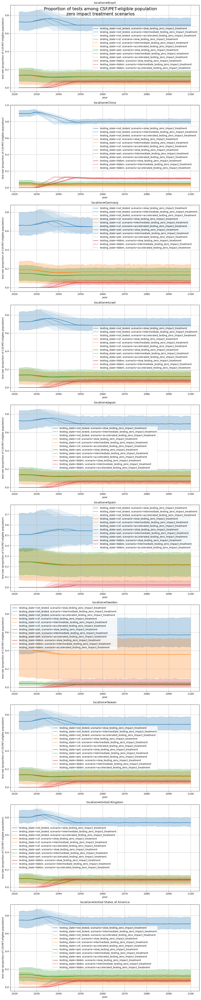

In [35]:
fig = plot_over_time_by_column_for_row_x_1(
    sim_test_rates.query("scenario in @zero_impact_scenarios"),
    'testing_state',
    'location',
    ylabel='test rate (proportion of CSF/PET-eligible population)',
    suptitle=(
        'Proportion of tests among CSF/PET-eligible population'
        '\nzero impact treatment scenarios'
    ),
)
for ax in fig.axes:
    ax.grid(True)
#     ax.set_xticks(ax.get_xticks()[::5])
plt.show()

# Plot existing test rates in with treatment scenarios for all countries

These graphs should look the same as the ones in the testing scenario.
And they do. Good.

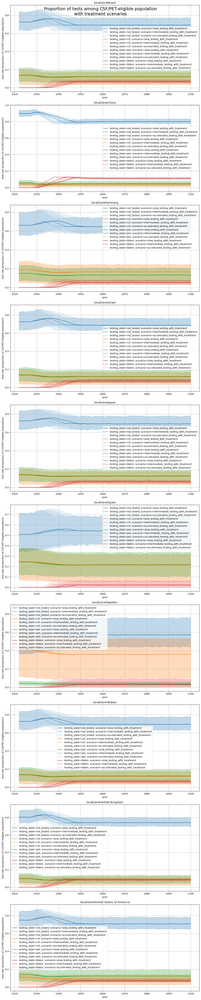

In [36]:
fig = plot_over_time_by_column_for_row_x_1(
    sim_test_rates.query("scenario in @with_treatment_scenarios"),
    'testing_state',
    'location',
    ylabel='test rate (proportion of CSF/PET-eligible population)',
    suptitle=(
        'Proportion of tests among CSF/PET-eligible population'
        '\nwith treatment scenarios'
    ),
)
for ax in fig.axes:
    ax.grid(True)
#     ax.set_xticks(ax.get_xticks()[::5])
plt.show()

# Read BBBM testing data

In [37]:
bbbm_test_eligibility_counts = load_sim_output(
    'counts_newly_eligible_for_bbbm_testing',
)
print_memory_usage(bbbm_test_eligibility_counts)
bbbm_test_eligibility_counts

('artifact_path', 'in', ['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/united_states_of_america.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/brazil.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/china.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/germany.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/israel.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/japan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/spain.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/sweden.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/taiwan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/mo

,age_group,artifact_path,bbbm_test_results,entity,entity_type,event_year,input_draw,measure,scenario,sex,sub_entity,value,location
0,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_newly_eligible_for_bbbm_testing,baseline,Female,,0.0,Spain
1,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_newly_eligible_for_bbbm_testing,baseline,Male,,0.0,Spain
2,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_newly_eligible_for_bbbm_testing,slow_testing_zero_impact_treatment,Female,,0.0,Spain
3,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_newly_eligible_for_bbbm_testing,slow_testing_zero_impact_treatment,Male,,0.0,Spain
4,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_newly_eligible_for_bbbm_testing,intermediate_testing_zero_impact_treatment,Female,,0.0,Spain
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12442495,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_newly_eligible_for_bbbm_testing,slow_testing_with_treatment,Male,,0.0,Brazil
12442496,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_newly_eligible_for_bbbm_testing,intermediate_testing_with_treatment,Female,,0.0,Brazil
12442497,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_newly_eligible_for_bbbm_testing,intermediate_testing_with_treatment,Male,,0.0,Brazil
12442498,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_newly_eligible_for_bbbm_testing,accelerated_testing_with_treatment,Female,,0.0,Brazil


In [38]:
bbbm_test_eligibility_counts.bbbm_test_results.unique()

['not_tested', 'positive', 'negative']
Categories (3, object): ['not_tested', 'positive', 'negative']

In [39]:
bbbm_test_counts = load_sim_output(
    'counts_bbbm_tests',
)
bbbm_test_counts

('artifact_path', 'in', ['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/united_states_of_america.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/brazil.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/china.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/germany.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/israel.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/japan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/spain.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/sweden.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/taiwan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/mo

,age_group,artifact_path,bbbm_test_results,entity,entity_type,event_year,input_draw,measure,scenario,sex,sub_entity,value,location
0,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_bbbm_tests,baseline,Female,,0.0,Spain
1,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_bbbm_tests,baseline,Male,,0.0,Spain
2,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_bbbm_tests,slow_testing_zero_impact_treatment,Female,,0.0,Spain
3,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_bbbm_tests,slow_testing_zero_impact_treatment,Male,,0.0,Spain
4,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,counts_bbbm_tests,intermediate_testing_zero_impact_treatment,Female,,0.0,Spain
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12442495,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_bbbm_tests,slow_testing_with_treatment,Male,,0.0,Brazil
12442496,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_bbbm_tests,intermediate_testing_with_treatment,Female,,0.0,Brazil
12442497,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_bbbm_tests,intermediate_testing_with_treatment,Male,,0.0,Brazil
12442498,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,counts_bbbm_tests,accelerated_testing_with_treatment,Female,,0.0,Brazil


# Check that BBBM tests are only occurring between ages 60-80

Yep. Good.

In [40]:
bbbm_test_eligibility_counts.query("value > 0").age_group.unique()

['65_to_69', '70_to_74', '75_to_79']
Categories (15, object): ['25_to_29' < '30_to_34' < '35_to_39' < '40_to_44' ... '80_to_84' < '85_to_89' < '90_to_94' < '95_plus']

In [41]:
bbbm_test_counts.query("value > 0").age_group.unique()

['65_to_69', '70_to_74', '75_to_79']
Categories (15, object): ['25_to_29' < '30_to_34' < '35_to_39' < '40_to_44' ... '80_to_84' < '85_to_89' < '90_to_94' < '95_plus']

# Divide to get BBBM testing rates for each year in each location

Aggregate over age groups and sexes to get a single number for each
location and year. Stratify by BBBM test results by broadcasting in the
numerator.

In [42]:
bbbm_test_rate = ops.ratio(
    bbbm_test_counts,
    bbbm_test_eligibility_counts,
     # Location is already in index columns, so stratify by year only
    strata=['event_year'],
    numerator_broadcast='bbbm_test_results',
)
bbbm_test_rate

,event_year,bbbm_test_results,input_draw,scenario,location,value,numerator_measure,denominator_measure,multiplier
0,2022,not_tested,11,accelerated_testing_with_treatment,Brazil,0.000000,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
1,2022,positive,11,accelerated_testing_with_treatment,Brazil,0.000000,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
2,2022,negative,11,accelerated_testing_with_treatment,Brazil,0.000000,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
3,2022,not_tested,11,accelerated_testing_with_treatment,China,0.000000,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
4,2022,positive,11,accelerated_testing_with_treatment,China,0.000000,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
...,...,...,...,...,...,...,...,...,...
414745,2100,positive,243,slow_testing_zero_impact_treatment,United Kingdom,0.225331,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
414746,2100,negative,243,slow_testing_zero_impact_treatment,United Kingdom,0.228298,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
414747,2100,not_tested,243,slow_testing_zero_impact_treatment,United States of America,0.000000,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1
414748,2100,positive,243,slow_testing_zero_impact_treatment,United States of America,0.227554,counts_bbbm_tests,counts_newly_eligible_for_bbbm_testing,1


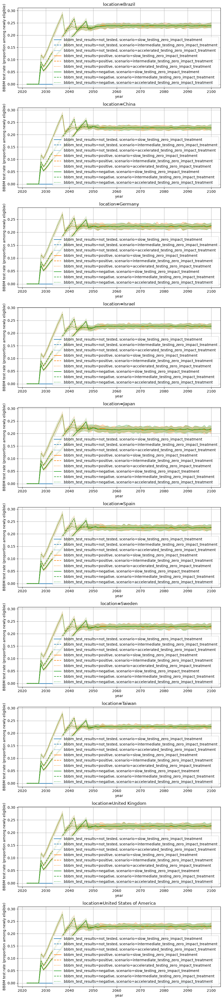

In [43]:
fig = plot_over_time_by_column_for_row_x_1(
    bbbm_test_rate.query("scenario in @zero_impact_scenarios"),
    'bbbm_test_results',
    'location',
    ylabel='BBBM test rate (proportion among newly eligible)',
    uncertainty=True,
    axes_width=9,
    axes_height=4,
)
for ax in fig.axes:
    ax.grid(True)
#     ax.set_xticks(ax.get_xticks()[::5])
plt.show()


# Check whether `not_tested` is ever nonzero among BBBM test counts

No, it's always zero. That's good.

In [44]:
# Good -- when counting tested simulants, the results are never "not tested"
bbbm_test_counts.query("bbbm_test_results == 'not_tested'").value.unique()

array([0.])

In [45]:
# On the other hand, among eligible simulants, there are lots of people
# who haven't been tested
bbbm_test_eligibility_counts.query("bbbm_test_results == 'not_tested'").value.unique()

array([   0., 2125., 1163., ..., 6069., 5830., 5610.])

# Check that among eligible similants, there are no positive tests

Yes, all counts of positive tests among eligible simulants are zero.

In [46]:
# Good -- among eligible simulants, no one has tested positive.
bbbm_test_eligibility_counts.query("bbbm_test_results == 'positive'").value.unique()

array([0.])

In [47]:
# On the other hand, among tested simulants, there are positive test results
len(bbbm_test_counts.query("bbbm_test_results == 'positive'").value.unique())

1844

# Check test sensitivity

Filter to testing scenario and/or treatment scenario since there are no BBBM tests in baseline.

In [48]:
bbbm_test_sensitivity = ops.ratio(
    bbbm_test_counts,
    bbbm_test_counts,
    strata=['event_year'],
    # prefilter_query="scenario=='bbbm_testing'",
    # Broadcast in numerator to get positive and negative test results
    numerator_broadcast='bbbm_test_results',
    # dropna=True, # Drop rows with 0 testing (baseline scenario and years < 2030)
)
bbbm_test_sensitivity

,event_year,bbbm_test_results,input_draw,scenario,location,value,numerator_measure,denominator_measure,multiplier
0,2022,not_tested,11,accelerated_testing_with_treatment,Brazil,NaN,counts_bbbm_tests,counts_bbbm_tests,1
1,2022,positive,11,accelerated_testing_with_treatment,Brazil,NaN,counts_bbbm_tests,counts_bbbm_tests,1
2,2022,negative,11,accelerated_testing_with_treatment,Brazil,NaN,counts_bbbm_tests,counts_bbbm_tests,1
3,2022,not_tested,11,accelerated_testing_with_treatment,China,NaN,counts_bbbm_tests,counts_bbbm_tests,1
4,2022,positive,11,accelerated_testing_with_treatment,China,NaN,counts_bbbm_tests,counts_bbbm_tests,1
...,...,...,...,...,...,...,...,...,...
414745,2100,positive,243,slow_testing_zero_impact_treatment,United Kingdom,0.496730,counts_bbbm_tests,counts_bbbm_tests,1
414746,2100,negative,243,slow_testing_zero_impact_treatment,United Kingdom,0.503270,counts_bbbm_tests,counts_bbbm_tests,1
414747,2100,not_tested,243,slow_testing_zero_impact_treatment,United States of America,0.000000,counts_bbbm_tests,counts_bbbm_tests,1
414748,2100,positive,243,slow_testing_zero_impact_treatment,United States of America,0.496523,counts_bbbm_tests,counts_bbbm_tests,1


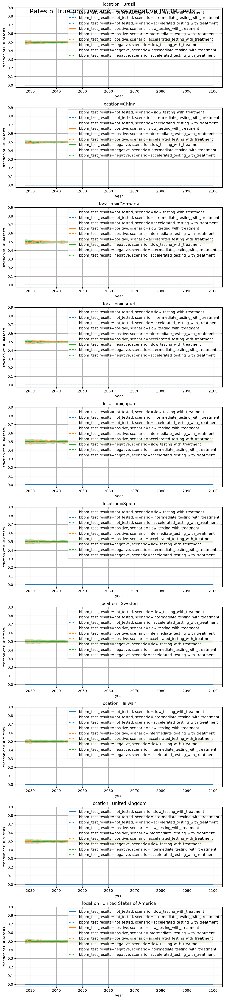

In [49]:
fig = plot_over_time_by_column_for_row_x_1(
    bbbm_test_sensitivity.query("scenario in @with_treatment_scenarios"),
    'bbbm_test_results',
    'location',
    ylabel='fraction of BBBM tests',
    suptitle='Rates of true positive and false negative BBBM tests',
    uncertainty=True,
    axes_width=9,
    axes_height=4,
)
for ax in fig.axes:
    # ax.set_xticks(ax.get_xticks()[::5])
    ax.set_yticks(np.arange(0,1, .1))
    ax.grid(True)
plt.show()


# Compute statistics on BBBM test sensitivity

In [50]:
bbbm_test_sensitivity_summary = ops.describe(
    bbbm_test_sensitivity.dropna().query("event_year >= 2030 and bbbm_test_results=='positive'"))
bbbm_test_sensitivity_summary

count  \
bbbm_test_results denominator_measure event_year location                 multiplier numerator_measure scenario                                            
positive          counts_bbbm_tests   2030       Brazil                   1          counts_bbbm_tests slow_testing_zero_impact_treatment           25.0   
                                                                                                       intermediate_testing_zero_impact_treatment   25.0   
                                                                                                       accelerated_testing_zero_impact_treatment    25.0   
                                                                                                       slow_testing_with_treatment                  25.0   
                                                                                                       intermediate_testing_with_treatment          25.0   
...                                                                                                                                                  ...   
                                      2100       United States of America 1          counts_bbbm_tests intermediate_testing_zero_impact_treatment   25.0   
                                                                                                       accelerated_testing_zero_impact_treatment    25.0   
                                                                                                       slow_testing_with_treatment                  25.0   
                                                                                                       intermediate_testing_with_treatment          25.0   
                                                                                                       accelerated_testing_with_treatment           25.0   

                                                                                                                                                       mean  \
bbbm_test_results denominator_measure event_year location                 multiplier numerator_measure scenario                                               
positive          counts_bbbm_tests   2030       Brazil                   1          counts_bbbm_tests slow_testing_zero_impact_treatment          0.494405   
                                                                                                       intermediate_testing_zero_impact_treatment  0.495844   
                                                                                                       accelerated_testing_zero_impact_treatment   0.498567   
                                                                                                       slow_testing_with_treatment                 0.494405   
                                                                                                       intermediate_testing_with_treatment         0.495844   
...                                                                                                                                                     ...   
                                      2100       United States of America 1          counts_bbbm_tests intermediate_testing_zero_impact_treatment  0.496689   
                                                                                                       accelerated_testing_zero_impact_treatment   0.496689   
                                                                                                       slow_testing_with_treatment                 0.496689   
                                                                                                       intermediate_testing_with_treatment         0.496689   
                                                                                                       accelerated_testing_with_treatment          0.496689   

                                                  

In [51]:
bbbm_test_sensitivity_summary['mean'].describe()

count    4260.000000
mean        0.499859
std         0.001584
min         0.491494
25%         0.499073
50%         0.499902
75%         0.500695
max         0.507375
Name: mean, dtype: float64

# Compute test result fractions among newly eligible simulants

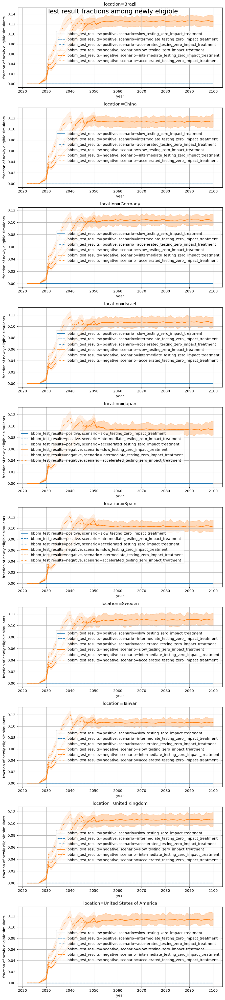

In [52]:
# TODO: Here would be a great place to use prefilter_query in the ratio
# function, once I implement it
bbbm_test_result_fractions_among_eligible = ops.ratio(
    bbbm_test_eligibility_counts,#.query("scenario=='bbbm_testing'"),
    bbbm_test_eligibility_counts,#.query("scenario=='bbbm_testing'"),
    strata=['event_year'],
    numerator_broadcast='bbbm_test_results',
    # @ syntax does not work here, because .query is called inside .ratio
    prefilter_query=f"scenario in {zero_impact_scenarios}",
)

fig = plot_over_time_by_column_for_row_x_1(
    bbbm_test_result_fractions_among_eligible.query("bbbm_test_results != 'not_tested'"),
    'bbbm_test_results',
    'location',
    ylabel='fraction of newly eligible simulants',
    suptitle='Test result fractions among newly eligible',
    uncertainty=True,
    axes_width=9,
    axes_height=4,
)
for ax in fig.axes:
    ax.grid(True)
    # ax.set_xticks(ax.get_xticks()[::5])
    # ax.set_yticks(np.arange(0,1, .1))
    # ax.semilogy()
plt.show()

# Plot numerators and denominators of BBBM test rate

In [53]:
bbbm_test_rate_numerator = ops.stratify(bbbm_test_counts, 'event_year')
bbbm_test_rate_denominator = ops.stratify(bbbm_test_eligibility_counts, 'event_year')
bbbm_test_rate_num_and_denom = pd.concat(
    [bbbm_test_rate_numerator, bbbm_test_rate_denominator],
    keys=['tests', 'newly_eligible'],
    names=['count'],
).reset_index('count').reset_index(drop=True)
bbbm_test_rate_num_and_denom

,count,event_year,input_draw,scenario,location,value
0,tests,2022,11,baseline,Brazil,0.0
1,tests,2022,11,baseline,China,0.0
2,tests,2022,11,baseline,Germany,0.0
3,tests,2022,11,baseline,Israel,0.0
4,tests,2022,11,baseline,Japan,0.0
...,...,...,...,...,...,...
276495,newly_eligible,2100,243,accelerated_testing_with_treatment,Spain,11906.0
276496,newly_eligible,2100,243,accelerated_testing_with_treatment,Sweden,9545.0
276497,newly_eligible,2100,243,accelerated_testing_with_treatment,Taiwan,14535.0
276498,newly_eligible,2100,243,accelerated_testing_with_treatment,United Kingdom,11796.0


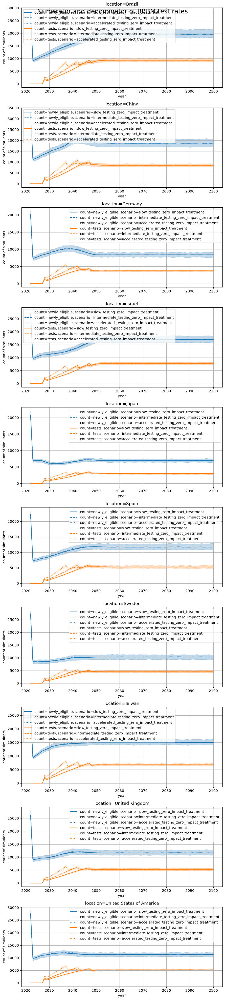

In [54]:
fig = plot_over_time_by_column_for_row_x_1(
    bbbm_test_rate_num_and_denom.query("scenario in @zero_impact_scenarios"),
    'count',
    'location',
    ylabel='count of simulants',
    suptitle='Numerator and denominator of BBBM test rates',
    axes_width=9,
    axes_height=4,
)
for ax in fig.axes:
    ax.grid(True)
    # ax.set_xticks(ax.get_xticks()[::5])
plt.show()

# Read in BBBM testing person-time data

In [55]:
pt_ever_eligible_bbbm = load_sim_output(
    'person_time_ever_eligible_for_bbbm_testing'
)
print_memory_usage(pt_ever_eligible_bbbm)
pt_ever_eligible_bbbm

('artifact_path', 'in', ['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/united_states_of_america.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/brazil.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/china.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/germany.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/israel.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/japan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/spain.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/sweden.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/taiwan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/mo

,age_group,alzheimers_disease_and_other_dementias,artifact_path,bbbm_test_results,entity,entity_type,event_year,input_draw,measure,scenario,sex,sub_entity,value,location
0,25_to_29,alzheimers_blood_based_biomarker_state,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_ever_eligible_for_bbbm_testing,baseline,Female,,0.000000,Spain
1,25_to_29,alzheimers_blood_based_biomarker_state,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_ever_eligible_for_bbbm_testing,baseline,Male,,0.000000,Spain
2,25_to_29,alzheimers_blood_based_biomarker_state,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_ever_eligible_for_bbbm_testing,slow_testing_zero_impact_treatment,Female,,0.000000,Spain
3,25_to_29,alzheimers_blood_based_biomarker_state,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_ever_eligible_for_bbbm_testing,slow_testing_zero_impact_treatment,Male,,0.000000,Spain
4,25_to_29,alzheimers_blood_based_biomarker_state,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_ever_eligible_for_bbbm_testing,intermediate_testing_zero_impact_treatment,Female,,0.000000,Spain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37327495,95_plus,alzheimers_disease_state,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_ever_eligible_for_bbbm_testing,slow_testing_with_treatment,Male,,240.673511,Brazil
37327496,95_plus,alzheimers_disease_state,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_ever_eligible_for_bbbm_testing,intermediate_testing_with_treatment,Female,,537.155373,Brazil
37327497,95_plus,alzheimers_disease_state,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_ever_eligible_for_bbbm_testing,intermediate_testing_with_treatment,Male,,240.673511,Brazil
37327498,95_plus,alzheimers_disease_state,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_ever_eligible_for_bbbm_testing,accelerated_testing_with_treatment,Female,,537.155373,Brazil


In [56]:
pt_eligible_bbbm = load_sim_output(
    'person_time_eligible_for_bbbm_testing'
)
print_memory_usage(pt_eligible_bbbm)
pt_eligible_bbbm

('artifact_path', 'in', ['/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/united_states_of_america.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/brazil.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/china.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/germany.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/israel.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/japan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/spain.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/sweden.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/model13.0/taiwan.hdf', '/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers/artifacts/mo

,age_group,artifact_path,bbbm_test_results,entity,entity_type,event_year,input_draw,measure,scenario,sex,sub_entity,value,location
0,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_eligible_for_bbbm_testing,baseline,Female,,0.0,Spain
1,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_eligible_for_bbbm_testing,baseline,Male,,0.0,Spain
2,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_eligible_for_bbbm_testing,slow_testing_zero_impact_treatment,Female,,0.0,Spain
3,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_eligible_for_bbbm_testing,slow_testing_zero_impact_treatment,Male,,0.0,Spain
4,25_to_29,/mnt/team/simulation_science/pub/models/vivari...,not_tested,bbbm_testing,testing,2022,11,person_time_eligible_for_bbbm_testing,intermediate_testing_zero_impact_treatment,Female,,0.0,Spain
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12442495,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_eligible_for_bbbm_testing,slow_testing_with_treatment,Male,,0.0,Brazil
12442496,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_eligible_for_bbbm_testing,intermediate_testing_with_treatment,Female,,0.0,Brazil
12442497,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_eligible_for_bbbm_testing,intermediate_testing_with_treatment,Male,,0.0,Brazil
12442498,95_plus,/mnt/team/simulation_science/pub/models/vivari...,negative,bbbm_testing,testing,2100,243,person_time_eligible_for_bbbm_testing,accelerated_testing_with_treatment,Female,,0.0,Brazil


# Plot BBBM testing rate (counts / eligible person-time)

In [57]:
bbbm_tests_per_eligible_pt = ops.ratio(
    bbbm_test_counts,
    pt_eligible_bbbm,
    strata='event_year',
    # numerator_broadcast='bbbm_test_results',
)
bbbm_tests_per_eligible_pt

,event_year,input_draw,scenario,location,value,numerator_measure,denominator_measure,multiplier
0,2022,11,baseline,Brazil,0.000000,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
1,2022,11,baseline,China,0.000000,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
2,2022,11,baseline,Germany,0.000000,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
3,2022,11,baseline,Israel,0.000000,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
4,2022,11,baseline,Japan,0.000000,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
...,...,...,...,...,...,...,...,...
138245,2100,243,accelerated_testing_with_treatment,Spain,0.195151,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
138246,2100,243,accelerated_testing_with_treatment,Sweden,0.197052,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
138247,2100,243,accelerated_testing_with_treatment,Taiwan,0.197524,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1
138248,2100,243,accelerated_testing_with_treatment,United Kingdom,0.198238,counts_bbbm_tests,person_time_eligible_for_bbbm_testing,1


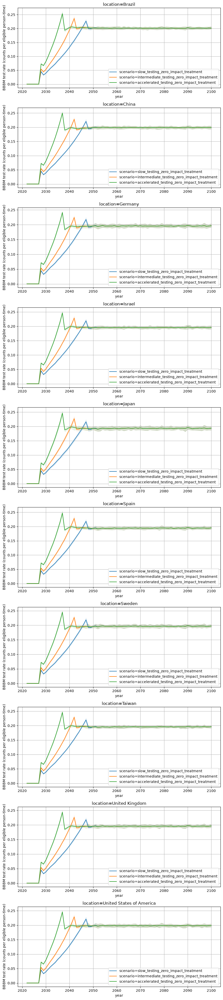

In [58]:
fig = plot_over_time_by_column_for_row_x_1(
    bbbm_tests_per_eligible_pt.query("scenario in @zero_impact_scenarios"),
    # 'bbbm_test_results',
    'scenario',
    'location',
    ylabel='BBBM test rate (counts per eligible person-time)',
    uncertainty=True,
    axes_width=9,
    axes_height=4,
)
for ax in fig.axes:
    # ax.set_xticks(ax.get_xticks()[::5])
    ax.grid(True)
plt.show()


# Compute prevalence of ever tested among ever eligible

In [59]:
pt_ever_eligible_bbbm.bbbm_test_results.unique()

['not_tested', 'positive', 'negative']
Categories (3, object): ['not_tested', 'positive', 'negative']

In [60]:
ever_tested_over_ever_eligible = ops.ratio(
    pt_ever_eligible_bbbm.query(
        "bbbm_test_results != 'not_tested'"),
    pt_ever_eligible_bbbm,
    strata=['event_year', 'age_group'],
    prefilter_query="alzheimers_disease_and_other_dementias == 'alzheimers_blood_based_biomarker_state'",
)#.query("scenario == 'bbbm_testing_and_treatment'")
ever_tested_over_ever_eligible

,event_year,age_group,input_draw,scenario,location,value,numerator_measure,denominator_measure,multiplier
0,2022,25_to_29,11,baseline,Brazil,NaN,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
1,2022,25_to_29,11,baseline,China,NaN,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
2,2022,25_to_29,11,baseline,Germany,NaN,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
3,2022,25_to_29,11,baseline,Israel,NaN,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
4,2022,25_to_29,11,baseline,Japan,NaN,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
...,...,...,...,...,...,...,...,...,...
2073745,2100,95_plus,243,accelerated_testing_with_treatment,Spain,0.678030,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
2073746,2100,95_plus,243,accelerated_testing_with_treatment,Sweden,0.717647,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
2073747,2100,95_plus,243,accelerated_testing_with_treatment,Taiwan,0.706667,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1
2073748,2100,95_plus,243,accelerated_testing_with_treatment,United Kingdom,0.683962,person_time_ever_eligible_for_bbbm_testing,person_time_ever_eligible_for_bbbm_testing,1


United States of America


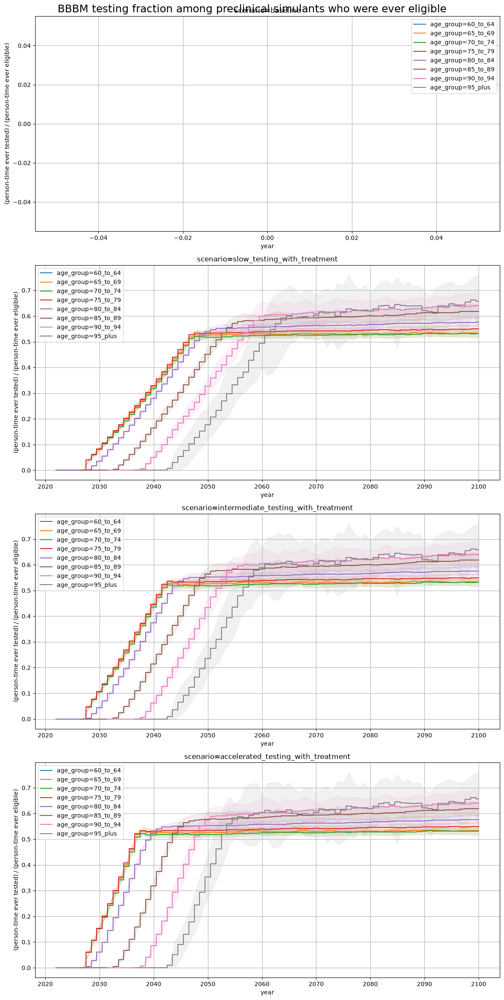

In [61]:
location = locations[0]
print(location)
# NOTE: I got "ValueError: unknown type object" when calling 
# .query("age_group < '60_to_64'") -- I fixed this by converting the
# dtype from Categorical to string. Using .loc doesn't work either
# because you can't compare unordered Categoricals. If we used an
# ordered Categorical for the age groups, that might make this easier.
# fig, ax = plt.subplots(figsize=(12, 6))
fig = plot_over_time_by_column_for_row_x_1(
    ever_tested_over_ever_eligible.astype({'age_group': str})
        .query("age_group >= '60_to_64' and location==@location"
               " and (scenario == 'baseline' or scenario in @with_treatment_scenarios)"),
        #.loc[ever_tested_over_ever_eligible.age_group < '60_to_64'],
        # .query("age_group in ['60_to_64', '65_to_69', '70_to_74', '75_to_79']"),
    'age_group',
    'scenario',
    # ax=ax,
    ylabel='(person-time ever tested) / (person-time ever eligible)',
    suptitle='BBBM testing fraction among preclinical simulants who were ever eligible',
    # plot_func='step',
    # where='post',
    ds='steps-mid',
)
for ax in fig.axes:
    # ax.set_xticks(ax.get_xticks()[::5])
    ax.grid(True)
plt.show()
